# Is J-space causally involved in integrating tool information at an LLM agent's decision step?

**A study-guide notebook for a small, honest pilot experiment.**

| | |
|---|---|
| **Model** | `Qwen/Qwen3.5-4B` (open weights, 32 layers, hidden size 2560) |
| **Lens** | Official pre-fitted Jacobian lens (`neuronpedia/jacobian-lens`, revision `qwen-n1000`) loaded with Anthropic's reference code [`jlens`](https://github.com/anthropics/jacobian-lens) |
| **Design** | **minimum run:** 4 held-out scenarios × 2 tasks × 3 conditions = 24 trials (+ 4 dev scenarios). This only shows the pipeline works; set `n_test_per_action` ≥ 12 in `config.py` for a real result. |
| **Version** | v2: concept-targeted ablation (observe first, then intervene), C2 replays C1's exact change sizes, harder retrieval, margin as secondary metric |
| **Runtime** | Google Colab **L4 or A100** GPU (about 20–40 min). Works on smaller GPUs with CPU offload, just slower. |

## 00 · What you will learn

By the end you should be able to explain, in your own words:

1. **Agent scaffold**: how a scripted "agent" collects facts from 3 tools into a memory.
2. **Residual stream** and the **Jacobian lens (J-lens)**: how we read "what the model is about to say" from inside it.
3. **Ablation**: how we delete a few directions from an activation vector, and why a **random control** is needed.
4. **The two metrics**: accuracy, and the integration specificity score **S**.
5. **Limits**: what a result here can and cannot tell us about AI welfare.

## Safety of claims (read this first)

* This notebook tests **one functional property** linked to Global Workspace Theory (GWT). It does **not** test consciousness, sentience, feelings or welfare.
* We first **observe** where task concepts (backup, critical, isolate…) appear in the J-lens, then remove **those concept directions at those places** (an orthogonal projection). That is a *concept-targeted J-lens-direction ablation*: **not** the paper's sparse non-negative J-space decomposition and **not** a removal of "the whole J-space".
* If any essential check fails (lens, hooks, controls), the notebook says **"NOT COMPLETED AS A J-SPACE EXPERIMENT"** and reports only what was actually measured.
* No number in the *Results* sections is typed by hand. Every number is computed from logged trials.

### How each section is organised

Every section answers the same five questions: **(a) What are we doing? (b) Why? (c) Code, (d) What output to expect, (e) What did we learn?**

## 01 · The research idea in plain words

### A tiny example

A security agent gets an alert about server **FIN-12**. A simple controller calls three tools:

| Tool | Returns |
|---|---|
| 1 · `get_alert()` | `{"server_id": "FIN-12", "risk": "high"}` |
| 2 · `get_asset_info()` | `{"server_id": "FIN-12", "critical_service": true}` |
| 3 · `get_backup_info()` | `{"server_id": "FIN-12", "backup_ready": true, "backup_id": "BK-07"}` |

Then we ask the model **one** of two questions about the **same** memory:

* **Integration task (I):** *"Which action is correct?"* To answer, the model must **combine 3 facts from 3 tools** with the rules: high risk + critical + backup ready → *fail over, then isolate*.
* **Retrieval task (T):** *"Which backup_id did tool 3 return?"* The model only has to **copy one value**: `BK-07`.

### Why compare these two?

Gurnee et al. (2026) found that the J-space behaves like a *global workspace*: it matters for **flexible** thinking (combining information, multi-step reasoning) but much less for **automatic** work (copying, simple recall). (See paper §3.5.)

So the theory makes a **falsifiable prediction** for our agent:

> If we remove the model's top J-lens directions, **integration** should get worse **more** than **retrieval** does, and **more** than when we remove random directions of the same size.

* **H1 (alternative):** J-lens ablation hurts integration selectively (S > 0).
* **H0 (null):** we cannot measure such a selective effect in this model and task.

### Link to AI welfare (careful)

Some theories say that what a system *experiences* depends on a global workspace. Finding a workspace-like *function* would add a small amount of evidence for **one indicator** used by those theories. It would **not** show experience. A null result would **not** disprove GWT or AI consciousness.

## 02 · Minimal background

### 2.1 The residual stream vector `h`

A transformer reads the prompt as a list of tokens. At every token position and every layer there is one vector of numbers, the **residual stream** `h` (2560 numbers for this model). Each layer reads `h`, computes something, and adds its result back to `h`.

> Think of it as a running set of notes for each token that every layer can read and edit.

In code, one layer's output has shape **`[batch, seq_len, hidden]`**, e.g. `[1, 450, 2560]`.

### 2.2 The Jacobian lens (J-lens)

We want to ask: *"Which words is this middle-layer vector `h` pushing the model to say, now or later?"*

The J-lens answers with one matrix per layer, the **average Jacobian**:

$$J_\ell = \mathbb{E}\left[\frac{\partial h_{\text{final}}}{\partial h_\ell}\right]$$

* $h_\ell$ = residual vector at layer ℓ, $h_{\text{final}}$ = residual at the last layer.
* $\partial h_{\text{final}} / \partial h_\ell$ = "if I nudge $h_\ell$ a little, how does the last layer change?" (a 2560 × 2560 matrix).
* $\mathbb{E}$ = averaged over 1000 web-text prompts and many positions, so $J_\ell$ describes the *general* effect, not one prompt.

Reading the lens: $\text{lens}(h_\ell) = \text{softmax}\big(W_U\,\text{norm}(J_\ell h_\ell)\big)$, where $W_U$ is the model's own output (unembedding) matrix. The highest-scoring tokens are the "words in the lens".

**J-lens vector of token t:** $v_t = J_\ell^\top (g \odot w_t)$, where $w_t$ is row t of $W_U$ and $g$ is the final RMSNorm gain.

*Why the gain $g$?* RMSNorm is $\text{norm}(x) = g \odot x / \text{rms}(x)$. So the lens logit of token t is
$$\frac{(g \odot w_t)^\top J_\ell h}{\text{rms}(J_\ell h)} = \frac{v_t \cdot h}{\text{rms}(J_\ell h)}.$$
The bottom part is the **same for every token** at one position, so ranking tokens by $v_t \cdot h$ gives exactly the lens ranking, and removing $v_t$ from $h$ makes token t's lens logit exactly 0. The simpler $J^\top w_t$ (spec §5.5) ignores the norm, so it would not do that. With $g = 1$ the two are the same.

**J-space** (paper §2.3) = vectors built from a *small number* (≈ ≤ 25) of J-lens vectors with non-negative weights. We do **not** compute that full sparse decomposition here. We use the paper's simpler ablation recipe instead (next).

### 2.3 Ablation: deleting directions from `h`

Removing one direction `v` from `h` (with strength α):

$$h_{\text{new}} = h - \alpha\,\frac{h \cdot v}{v \cdot v}\,v$$

* α = 0: nothing changes. α = 1: the part of `h` that points along `v` is fully removed. (We only allow 0 ≤ α ≤ 1.)
* With **k** vectors $V = [v_1 \dots v_k]$ we remove the projection onto all of them at once: $h_{\text{new}} = h - \alpha\,P_V h$.
* **How we compute $P_V$:** with an SVD, $V = U S Q$. The rows of $Q$ are an orthonormal basis of span(V), so $P_V h = Q^\top (Q h)$. We do **not** form $V V^\top$, because that squares the condition number. Tokens like `"backup"` and `" backup"` have almost parallel J-lens vectors, and in float32 the $V V^\top$ route can blow up. Singular values below $10^{-4} \times$ the largest are treated as 0, and we log the *effective rank*.
* With k = 1 this is exactly the one-direction formula above (a unit test checks this).

**Which directions do we remove? Observe first, then intervene (v2).**
1. Run the model **clean** (no edits) and read the J-lens at every (layer, position) of a band.
2. Look for a **pre-registered list of task concepts**: `high, low, medium, risk, critical, service, backup, ready, isolate, isolation, monitor, monitoring, fail, failover, revoke, credentials, safe, true, false` (every single-token spelling, e.g. `"backup"` and `" backup"`).
3. A concept is **present** at a site if it is in the lens **top-20** there and it is *not* one of the clean model's own top-10 next-token guesses (so we hit internal thinking, not the word about to be written).
4. In C1, remove exactly those concept directions at exactly those sites. Sites with no concept are left alone.

*Why not the paper's "top-10 at every site" recipe (§3.5.2)?* We tried it in v1: the top-10 at the answer position were `<|endoftext|>`, `<|im_end|>`, blank lines and `**`, i.e. formatting signals, not the decision. That recipe tests "the J-space in general"; our question is about the **decision content**, so we target it. (The old recipe is still available as `selection="topk"`, now with special and punctuation tokens excluded.)

> **Important limit (spec §5.9).** The paper defines the J-space as *sparse, non-negative* combinations of J-lens vectors, found by "gradient pursuit". Our projection onto the span of the top-k vectors is **not** that decomposition: it is a simpler linear projection, and it even removes parts with negative coefficients. So we call it a **top-k J-lens-direction ablation**, never "J-space ablation".

### 2.4 Why a random control?

Any big change to `h` can break a model. If J-ablation hurts integration, maybe it is just *damage*, not anything special about J-lens directions. So condition **C2** is a **norm-matched random perturbation** (spec §5.8):

$$m = \|h_J - h\|_2 \text{ (recorded in the C1 run)},\qquad r \sim \mathcal{N}(0, I_d),\qquad \Delta_R = -m\,\frac{r}{\|r\|_2},\qquad h_R = h + \Delta_R .$$

* Same layer, same position, **exactly the same length** $m$, but a random direction. Only a difference *between* J and random counts.
* **$m$ is copied from the C1 run, site by site.** In v1 the random hook re-measured $m$ on its *own* activations; noise added at layer 12 made layer 13 bigger, and so on, so C2 ended up 1.68× bigger than C1. Copying C1's numbers makes the sizes equal by construction.
* A fresh $r$ is drawn for every position. Its seed comes from (base seed, layer, prompt hash), so the same trial always gets the same $r$, whatever order trials run in.
* Note the name: this is a random **perturbation**, not "removing a random direction".

The worked toy examples (Jacobian by autograd, the R² ablation, the random control) run in **section 03b**, right after the code is imported.

## 03 · Setup, reproducibility and hardware check

**What:** install packages (Colab only), import the project code, fix random seeds, create a run folder, and check the GPU.

**Why:** a result is only useful if someone else can repeat it. Every run writes its own folder `results/run_<UTC time>/`, so earlier runs are never overwritten.

### Running on Google Colab
1. *Runtime → Change runtime type →* **L4** or **A100** GPU. (A T4 works but has no native bf16, so it is slow.)
2. Upload the whole `experiment/` folder to Google Drive as `MyDrive/jspace_experiment/`.
3. Run the next cell. It mounts Drive, installs `requirements.txt` (including `jlens` pinned to a commit), and moves into the folder.

Locally, open this notebook from inside `experiment/` and the cell just uses the current folder.

In [24]:
import os
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    EXPERIMENT_DIR = "/content/drive/MyDrive/jspace_experiment"   # <- change if you put it elsewhere
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", f"{EXPERIMENT_DIR}/requirements.txt"], check=True)
else:
    EXPERIMENT_DIR = os.getcwd()

os.chdir(EXPERIMENT_DIR)
if EXPERIMENT_DIR not in sys.path:
    sys.path.insert(0, EXPERIMENT_DIR)

# Always use the CURRENT code in jspace_pilot/: drop any older copy an earlier run left in memory,
# so you never need to restart the kernel just because a .py file changed.
for _name in [m for m in sys.modules if m == "jspace_pilot" or m.startswith("jspace_pilot.")]:
    del sys.modules[_name]
import jspace_pilot

NOTEBOOK_CODE_VERSION = "2.0.0"   # this notebook was written for this version of jspace_pilot/
if jspace_pilot.__version__ != NOTEBOOK_CODE_VERSION:
    raise RuntimeError(
        f"This notebook expects jspace_pilot v{NOTEBOOK_CODE_VERSION}, but the code folder has "
        f"v{jspace_pilot.__version__}. Close and reopen the notebook (File > Revert File) so both come from the same version."
    )
print("experiment folder:", EXPERIMENT_DIR)
print("python:", sys.executable)
print("jspace_pilot version:", jspace_pilot.__version__, "(matches this notebook)")

experiment folder: /home/kali/Desktop/Anthropic_reserach/takehome_v3/experiment
python: /home/kali/miniconda3/envs/msc_dissertation/bin/python
jspace_pilot version: 2.0.0 (matches this notebook)


**What:** run the unit tests before touching the model.

**Why:** they check the dataset rules, the statistics, the hook maths on tiny fake tensors, and that **this notebook matches the code** (every name it imports exists). If these fail, nothing later can be trusted.

**How:** pytest runs *inside this kernel* (same Python, same packages as the experiment), and its full report is printed, including the reason for any failure.

**Expected output:** a line like `33 passed`. Any `failed` means stop: the report above the error says which test and why.

In [25]:
import pytest

exit_code = int(pytest.main(["-q", "-p", "no:cacheprovider", "tests"]))
print("pytest exit code:", exit_code, "(0 = all passed)")
assert exit_code == 0, "unit tests failed: read the pytest report just above, fix, then rerun this cell"

.................................                                        [100%]
=============================== warnings summary ===============================
../../../../miniconda3/envs/msc_dissertation/lib/python3.11/site-packages/_pytest/config/__init__.py:1345
  /home/kali/miniconda3/envs/msc_dissertation/lib/python3.11/site-packages/_pytest/config/__init__.py:1345: PytestAssertRewriteWarning: Module already imported so cannot be rewritten; anyio
    self._mark_plugins_for_rewrite(hook, disable_autoload)

-- Docs: https://docs.pytest.org/en/stable/how-to/capture-warnings.html
33 passed, 1 warning in 0.21s
pytest exit code: 0 (0 = all passed)


**What:** preflight checks, *before* the 9 GB model is loaded.

**Why:** most failures are set-up problems, not science problems: a missing package, a kernel using a different Python environment, an old kernel still holding the GPU, a notebook file older than the code, a results folder that cannot be written. This cell finds them in seconds and prints how to fix each one.

**Expected output:** one line per check: `✓ OK`, `! WARN` (the run can continue) or `✗ FAIL` (fix first, using the `-> fix:` hint), then `PREFLIGHT: PASSED`.

In [26]:
from jspace_pilot.preflight import print_report, run_preflight

PREFLIGHT_OK = print_report(run_preflight())
assert PREFLIGHT_OK, "preflight failed: see the ✗ items and their fixes above"

  ✓ OK   python                   3.11.15  (/home/kali/miniconda3/envs/msc_dissertation/bin/python)
  ✓ OK   package torch            2.14.1
  ✓ OK   package transformers     5.19.0
  ✓ OK   package accelerate       1.15.0
  ✓ OK   package huggingface_hub  1.33.0
  ✓ OK   package jlens            0.1.0
  ✓ OK   package numpy            2.4.6
  ✓ OK   package pandas           3.0.6
  ✓ OK   package matplotlib       3.11.2
  ✓ OK   package pytest           9.1.1
  ✓ OK   jlens API                JacobianLens, ActivationRecorder, from_hf, Layout
  ✓ OK   CUDA GPU                 NVIDIA GeForce RTX 5060 Laptop GPU, 8.0 GiB
  ! WARN free VRAM                2.5 of 8.0 GiB free: 5.5 GiB already used by another process
         -> fix: an old notebook kernel may still hold the model: restart/shut down other kernels
  ✓ OK   model in local cache     Qwen/Qwen3.5-4B
  ✓ OK   notebook matches code    every jspace_pilot import in the notebook exists
  ✓ OK   results folder writable  /home/kali/De

**What:** load the configuration, fix seeds, create the run folder and start logging.

`ExperimentConfig` is a *frozen* dataclass: every setting that could change a result is in one place, and it cannot be modified by accident later. Its full contents are saved to `run_metadata.json`.

In [27]:
import random
from dataclasses import replace

import numpy as np
import pandas as pd
import torch

from jspace_pilot.config import CONDITIONS, TASK_TYPES, ExperimentConfig
from jspace_pilot.reporting import environment_info, new_run_dir, save_json, setup_logging

CONFIG = ExperimentConfig()
# Example override (only BEFORE the test split is run): CONFIG = replace(CONFIG, n_gpu_layers=20)

random.seed(CONFIG.seed)
np.random.seed(CONFIG.seed)
torch.manual_seed(CONFIG.seed)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

RUN_ID, RUN_DIR = new_run_dir(CONFIG.results_root)
log = setup_logging(RUN_DIR)
log.info("run %s -> %s", RUN_ID, RUN_DIR)
pd.set_option("display.width", 160, "display.max_colwidth", 80)

18:25:30 | INFO    | jspace_pilot | run run_20261109T182530Z -> /home/kali/Desktop/Anthropic_reserach/takehome_v3/experiment/results/run_20261109T182530Z


**What:** print library versions and the GPU, and decide the **run mode**.

* `full`: CUDA GPU available, so we will try the real experiment.
* `design_or_demo`: no GPU. We still build and check the dataset, but we do not pretend to run the experiment.

In [28]:
ENV = environment_info()
for key, value in ENV.items():
    print(f"{key:>22}: {value}")

if not ENV["cuda_available"]:
    RUN_MODE = "design_or_demo"
    print("\nNo CUDA GPU -> RUN_MODE = design_or_demo (model sections will be skipped).")
else:
    RUN_MODE = "full"
    major, _ = torch.cuda.get_device_capability(0)
    if major < 8:
        print("\nWARNING: this GPU has no native bf16 (e.g. T4). It will work but slowly. Prefer L4/A100.")
print("\nRUN_MODE =", RUN_MODE)

         execution_utc: 2026-11-09T18:25:30.138145+00:00
                python: 3.11.15
              platform: Linux-6.18.33.2-microsoft-standard-WSL2-x86_64-with-glibc2.42
                 torch: 2.14.1+cu130
          transformers: 5.19.0
            accelerate: 1.15.0
       huggingface_hub: 1.33.0
                 jlens: 0.1.0
  jlens_install_source: {"dir_info": {"editable": true}, "url": "file:///home/kali/Desktop/jacobian-lens"}
        cuda_available: True
              gpu_name: NVIDIA GeForce RTX 5060 Laptop GPU
          gpu_vram_gib: 7.96
          cuda_version: 13.0
        bf16_supported: True

RUN_MODE = full


## 03b · Toy math checks (CPU, before any model)

**What:** run the maths on tiny examples where you can check every number by hand.

**Why:** if the formulas are wrong on a 2-number example, they are wrong on the 2560-number model too. These checks are required by the spec (§5.2, §5.6, §5.8, §5.12), and the notebook refuses to continue if any fails.

### Step 1 · What a Jacobian is (§5.2)

Take $f([x_1, x_2]) = [2x_1 + x_2,\; x_1 + 3x_2]$. The Jacobian is the table of partial derivatives:

$$J = \begin{bmatrix} \partial f_1/\partial x_1 & \partial f_1/\partial x_2 \\ \partial f_2/\partial x_1 & \partial f_2/\partial x_2 \end{bmatrix} = \begin{bmatrix} 2 & 1 \\ 1 & 3 \end{bmatrix}$$

**Meaning:** "if I nudge the input by δ, the output moves by about J·δ." Example: x = [3, 2] gives f(x) = [8, 9]. With δ = [0.1, 0] the output moves by [0.2, 0.1] = J·δ.

We get J three ways and check that they agree:
1. by hand,
2. with `torch.autograd.functional.jacobian` (what jlens does at scale, via backprop),
3. with **finite differences**: change one input a tiny bit and see how much the output moves, $(f(x+\epsilon e_j) - f(x-\epsilon e_j)) / 2\epsilon$.

In the real lens, $J_\ell = \mathbb{E}[\partial h_{\text{final}} / \partial h_\ell]$ is the same idea, but 2560 × 2560 and averaged over 1000 prompts. We **load** that matrix (fitting it takes hours of GPU time); we do not refit it.

**Expected output:** three identical 2 × 2 matrices and three `True`s.

In [29]:
from jspace_pilot.toy_math import test_projection_invariants, toy_direction_ablation, verify_toy_autograd

TOY_CHECKS = {"autograd": verify_toy_autograd()}
for key, value in TOY_CHECKS["autograd"].items():
    print(f"{key:>28}: {value}")

                           x: [3.0, 2.0]
                        f(x): [8.0, 9.0]
                  J_analytic: [[2.0, 1.0], [1.0, 3.0]]
                  J_autograd: [[2.0, 1.0], [1.0, 3.0]]
         J_finite_difference: [[1.9998549222946167, 0.9996890425682068], [0.9994506239891052, 3.0002591609954834]]
             f(x+delta)-f(x): [0.19999980926513672, 0.10000038146972656]
                   J @ delta: [0.20000000298023224, 0.10000000149011612]
   autograd_matches_analytic: True
finite_diff_matches_analytic: True
           taylor_rule_holds: True


### Step 2 · From Jacobian to J-lens direction to ablation, in R² (§5.6)

Teaching numbers only, not an AI result: $J = \begin{bmatrix}2&1\\1&3\end{bmatrix}$, $h = [3, 2]$, token row $w = [1, -1]$ (here $g = 1$).

| step | formula | value |
|---|---|---|
| transport | $J h$ | [8, 9] |
| token score | $w \cdot (J h)$ | 8 − 9 = −1 |
| J-lens direction | $v = J^\top w$ | [1, −2] |
| same score from $v$ | $v \cdot h$ | 3 − 4 = −1 ✓ |
| projection of h on v | $\frac{h\cdot v}{v \cdot v} v$ | (−1/5)·[1, −2] = [−0.2, 0.4] |
| ablated | $h - \text{proj}$ | [3.2, 1.6] |
| check | $v \cdot h_{\text{ablated}}$ | 0 |
| score after | $w \cdot (J h_{\text{ablated}}) = w \cdot [8, 8]$ | 0 |

**What it shows:** we removed exactly the part of `h` that made this token score, and only that part. It does **not** delete the JSON facts or the whole representation.

**Expected output:** the same numbers as the table.

In [30]:
TOY_CHECKS["r2_ablation"] = toy_direction_ablation()
for key, value in TOY_CHECKS["r2_ablation"].items():
    print(f"{key:>32}: {value}")

                               J: [[2.0, 1.0], [1.0, 3.0]]
                               h: [3.0, 2.0]
                         w_token: [1.0, -1.0]
                             J h: [8.0, 9.0]
          score_before = w.(J h): -1.0
                       v = J^T w: [1.0, -2.0]
        v.h (should equal score): -1.0
            projection of h on v: [-0.20000000298023224, 0.4000000059604645]
                       h_ablated: [3.200000047683716, 1.600000023841858]
                     v.h_ablated: 0.0
               ||h_ablated - h||: 0.4472135901451111
                     J h_ablated: [8.0, 8.0]
   score_after = w.(J h_ablated): 0.0


### Step 3 · Projection and control invariants (§5.12)

**What:** random 64-dimensional data checks every property the real intervention relies on:
* $v \cdot h$ equals the lens logit $w^\top \text{diag}(g) J h$;
* α = 0 changes nothing, and α = 1 leaves $v \cdot h_{\text{new}} = 0$;
* the k-vector SVD projection with k = 1 equals the one-direction formula;
* after projection, `h` is orthogonal to every selected vector, and projecting twice changes nothing;
* adding an **exact duplicate** and a **near duplicate** vector does not change the projection, and the effective rank stays k (this is the float32 stability fix);
* the random control has exactly the same length as the J change;
* no NaN or Inf values.

**Expected output:** a list of checks, all `True`. If any is `False`, the cell stops the notebook.

In [31]:
TOY_CHECKS["invariants"] = test_projection_invariants()
for name, ok in TOY_CHECKS["invariants"].items():
    print(("  ✓ " if ok else "  ✗ ") + name)
TOY_MATH_OK = (
    all(TOY_CHECKS["invariants"].values())
    and TOY_CHECKS["autograd"]["autograd_matches_analytic"]
    and TOY_CHECKS["autograd"]["finite_diff_matches_analytic"]
    and abs(TOY_CHECKS["r2_ablation"]["score_after = w.(J h_ablated)"]) < 1e-5
)
assert TOY_MATH_OK, "toy maths failed: do not run the model experiment"
print("\nTOY_MATH_OK =", TOY_MATH_OK)

  ✓ v has shape [d]
  ✓ w^T diag(g) J h == v . h
  ✓ alpha=0 leaves h unchanged
  ✓ alpha=1 gives v . h_new ~ 0
  ✓ k=1 span projection == remove_direction
  ✓ residual orthogonal to every selected vector
  ✓ projection is idempotent (P P h = P h)
  ✓ duplicate/near-duplicate vectors: same projection
  ✓ duplicate/near-duplicate vectors: rank stays k
  ✓ ||delta_random|| == ||delta_J||
  ✓ no NaN/Inf anywhere

TOY_MATH_OK = True


## 04 · Build the synthetic benchmark

**What:** create 8 scenarios (4 *dev* + 4 held-out *test*, one per action in each split), each with an integration question and a retrieval question.

**Why:** labels must come from a **program**, not from a model, so they are guaranteed correct.

### Decision rules (the ground truth)

| risk | critical_service | backup_ready | correct action |
|---|---|---|---|
| not `high` | any | any | keep monitoring |
| `high` | `false` | any | isolate now |
| `high` | `true` | `true` | fail over, then isolate |
| `high` | `true` | `false` | revoke credentials, monitor, plan safe isolation |

### Design details
* **Stratified test split:** exactly `n_test_per_action` test scenarios per action (1 in this minimum run).
* **Counterbalanced letters:** within each split and task, the correct option is A, B, C and D equally often. So a model that always says "A" scores only 25%.
* **Unique ids:** every alerted server id and its backup id appear in only one scenario, so dev and test never overlap.
* **Tool 3 lists 3 servers (v2):** the alerted server plus 2 decoy servers, each with its own `backup_ready` and `backup_id`, in random order. Both tasks must first find the right server. For retrieval, 2 of the 3 wrong options are decoy ids that **are** in memory, so it is a real lookup. (In v1 retrieval was 100% in every condition and could not show any drop.)
* *Limitation:* all scenarios share one template and one rule set, so results may not generalise beyond it.

In [32]:
from jspace_pilot.reporting import save_jsonl
from jspace_pilot.scenarios import generate_scenarios, split_scenarios
from jspace_pilot.validation import validate_scenarios

SCENARIOS = generate_scenarios(CONFIG.seed, CONFIG.n_dev, CONFIG.n_test_per_action, CONFIG.n_backup_entries)
DEV, TEST = split_scenarios(SCENARIOS)

DATASET_CHECKS = validate_scenarios(SCENARIOS, CONFIG.n_test_per_action)   # raises if anything is wrong
DATASET_OK = True
print(f"{len(DEV)} dev + {len(TEST)} test scenarios. All dataset checks passed:")
for check in DATASET_CHECKS:
    print("  ✓", check)

save_jsonl([s.to_dict() for s in SCENARIOS], RUN_DIR / "scenarios.jsonl")

4 dev + 4 test scenarios. All dataset checks passed:
  ✓ decision rule correct on all 12 input combinations
  ✓ scenario, server and backup ids are unique (no dev/test overlap)
  ✓ test split balanced: 1 scenarios per semantic action
  ✓ every label comes from expected_action(), not from a model
  ✓ every question has exactly 4 options (A-D) and exactly 1 correct option
  ✓ option letters match the semantic answers after shuffling
  ✓ retrieval answer = tool 3 entry of the alerted server; decoy ids from memory are wrong options
  ✓ memory is identical for both tasks of a scenario; no answer key in prompts


PosixPath('/home/kali/Desktop/Anthropic_reserach/takehome_v3/experiment/results/run_20261109T182530Z/scenarios.jsonl')

**What:** look at the data as a table and check the balance.

**Expected output:** a table of scenarios, then two count tables. In the test split every action has 6 rows, and every letter is correct 6 times for each task.

In [33]:
scenario_df = pd.DataFrame([s.to_dict() for s in SCENARIOS]).drop(columns=["integration_options", "retrieval_options"])
display(scenario_df.head(8))

test_df_view = scenario_df[scenario_df.split == "test"]
display(test_df_view["semantic_correct_action"].value_counts().rename("test scenarios per action").to_frame())
display(pd.DataFrame({
    "integration": test_df_view["correct_integration_letter"].value_counts(),
    "retrieval": test_df_view["correct_retrieval_letter"].value_counts(),
}).rename_axis("correct letter (test)"))

,scenario_id,split,server_id,risk,critical_service,backup_ready,backup_id,decoy_backups,target_backup_index,semantic_correct_action,correct_integration_letter,correct_retrieval_letter
0,case_001,dev,OPS-37,high,False,True,BK-526,"((CRM-24, True, BK-283), (WEB-96, True, BK-893))",0,isolate_now,B,A
1,case_002,dev,CRM-85,high,True,True,BK-001,"((CRM-45, False, BK-960), (CRM-49, True, BK-385))",2,failover_then_isolate,C,B
2,case_003,dev,WEB-24,high,True,False,BK-716,"((HR-01, False, BK-920), (OPS-87, False, BK-036))",0,contain_and_plan,A,D
3,case_004,dev,MAIL-27,low,True,False,BK-925,"((PAY-90, True, BK-065), (CRM-17, True, BK-274))",0,monitor,D,C
4,case_005,test,PAY-83,high,False,False,BK-773,"((MAIL-13, False, BK-281), (FIN-98, False, BK-997))",1,isolate_now,B,A
5,case_006,test,OPS-63,high,True,False,BK-052,"((CRM-05, False, BK-606), (HR-40, True, BK-667))",1,contain_and_plan,D,B
6,case_007,test,HR-87,low,True,True,BK-562,"((MAIL-77, True, BK-918), (HR-93, True, BK-439))",0,monitor,A,C
7,case_008,test,CRM-54,high,True,True,BK-540,"((OPS-93, False, BK-740), (FIN-82, False, BK-544))",2,failover_then_isolate,C,D


,test scenarios per action
semantic_correct_action,
isolate_now,1
contain_and_plan,1
monitor,1
failover_then_isolate,1


,integration,retrieval
correct letter (test),,
A,1,1
B,1,1
C,1,1
D,1,1


## 05 · Simulate the tool-using agent

**What:** run the scripted controller for one scenario and print exactly what the model will read.

```
scenario ──► tool_1 get_alert ──► tool_2 get_asset_info ──► tool_3 get_backup_info
                                                                   │
                                                                   ▼
                                       oracle memory (3 JSON lines, never edited)
                                                                   │
                         system rules + memory + ONE question + options A–D
                                                                   │
                                                                   ▼
                                    LLM: one forward pass ──► next-token = answer letter
```

**Why "scripted":** the tools are plain Python functions and always run in the same order. This is a *structured tool-use workflow*, **not** an autonomous agent that plans its own tool calls. That is on purpose: the memory must be identical in every condition.

**Expected output:** the system prompt, then the user message for the integration task, then just the question part of the retrieval task. The memory block is the same in both.

In [34]:
from jspace_pilot.agent import build_messages, run_scripted_agent

example = DEV[1]
print("Hidden facts:", {k: example.to_dict()[k] for k in ("server_id", "risk", "critical_service", "backup_ready", "backup_id")})
print("Correct action (from the rule):", example.semantic_correct_action)
print("Correct letters -> integration:", example.correct_integration_letter, "| retrieval:", example.correct_retrieval_letter)
print("\n=== AGENT MEMORY ===")
print(run_scripted_agent(example).render())

messages = build_messages(example, "integration")
print("\n=== SYSTEM MESSAGE ===\n" + messages[0]["content"])
print("\n=== USER MESSAGE (integration) ===\n" + messages[1]["content"])
print("\n=== QUESTION PART (retrieval) ===\n" + build_messages(example, "retrieval")[1]["content"].split("QUESTION", 1)[1])

Hidden facts: {'server_id': 'CRM-85', 'risk': 'high', 'critical_service': True, 'backup_ready': True, 'backup_id': 'BK-001'}
Correct action (from the rule): failover_then_isolate
Correct letters -> integration: C | retrieval: B

=== AGENT MEMORY ===
[1] get_alert -> {"server_id": "CRM-85", "risk": "high"}
[2] get_asset_info -> {"server_id": "CRM-85", "critical_service": true}
[3] get_backup_info -> {"backups": [{"server_id": "CRM-45", "backup_ready": false, "backup_id": "BK-960"}, {"server_id": "CRM-49", "backup_ready": true, "backup_id": "BK-385"}, {"server_id": "CRM-85", "backup_ready": true, "backup_id": "BK-001"}]}

=== SYSTEM MESSAGE ===
You are a security operations assistant. An automated controller has already called three tools and stored their outputs in memory. The alert (tool 1) names one server; tool 3 lists backups for several servers, so always use the entry whose server_id matches the alerted server. Answer the question using only that memory.

DECISION RULES (for the a

**What we learned:** both tasks see the **same** rules and memory. Only the last few lines (question and options) differ. The answer key never appears in the prompt.

## 06 · Load the model and run the baseline

**What:** load `Qwen/Qwen3.5-4B` in **bf16** (16-bit) precision.

**Why bf16 and no quantisation:** the lens was fitted on this exact checkpoint in bf16. 8-bit or 4-bit weights would change the activations, and the lens might no longer fit them.

**Memory:** the model is about 9 GB. On a 24 GB+ GPU everything sits on the GPU. On a smaller GPU, `load_model` keeps the embedding, the output head and the first N layers on the GPU, and *streams* the remaining layers from CPU RAM. This gives the same numbers, just slower.

**Expected output:** a log line with the device plan and the load time (1–5 minutes on first download).

In [35]:
import time

from jspace_pilot.model_io import letter_token_variants, load_model

if RUN_MODE == "full":
    t0 = time.perf_counter()
    LOADED = load_model(CONFIG)
    log.info("model loaded in %.0fs | %d/%d blocks on GPU | d_model=%d",
             time.perf_counter() - t0, LOADED.n_gpu_layers, LOADED.n_layers, LOADED.d_model)
    LETTER_VARIANTS = letter_token_variants(LOADED.tokenizer)
    print("Token ids that spell each answer letter:", LETTER_VARIANTS)
    print("Model commit:", getattr(LOADED.hf_model.config, "_commit_hash", None))
else:
    LOADED = None
    print("Skipped (RUN_MODE =", RUN_MODE, ")")

18:25:31 | INFO    | jspace_pilot.model_io | VRAM free 2.50 GiB | fixed 2.37 GiB | per block 0.210 GiB | reserve 1.8 GiB -> 0/32 blocks on GPU


Loading weights: 100%|██████████| 426/426 [00:01<00:00, 410.96it/s]


18:25:32 | WARNING | accelerate.big_modeling | Some parameters are on the meta device because they were offloaded to the cpu.
18:25:32 | INFO    | jspace_pilot | model loaded in 2s | 0/32 blocks on GPU | d_model=2560
Token ids that spell each answer letter: {'A': [32, 357], 'B': [33, 417], 'C': [34, 351], 'D': [35, 414]}
Model commit: None


### How we read the model's answer: one forward pass, no sampling

* **Prefill** = the model reads the whole prompt in one forward pass and gives a probability for every possible next token.
* **Decode** would then generate tokens one by one, using a **KV cache** (stored attention keys and values) so it does not recompute the prompt.
* **We never decode.** The answer is the *first* token, so one prefill pass is enough. This means the hooks see exactly one forward pass with a fixed length, so there are no shifting token positions and no cache to worry about.

From that one pass we compute two things:

| | rule | role |
|---|---|---|
| **strict answer** (`predicted_letter`) | top-1 token over the *whole* vocabulary. If it is not A/B/C/D, the output is **invalid** and counts as **wrong**. This equals greedy decoding of one token. | **primary metric** |
| **restricted answer** (`restricted_letter`) | best of the 4 letter tokens only (option scoring) | diagnostic |

We also log the **margin** = log p(correct letter) − log p(best wrong letter). Positive means the correct letter wins.

**What the next cell does:** renders the chat template (thinking turned **off**, so the first token should be the answer), then runs one integration and one retrieval prompt and prints the top-5 next tokens.

**Expected output:** the end of the formatted prompt, and for each task a list of top tokens with the predicted and expected letters.

In [36]:
from jspace_pilot.experiment import ExperimentContext, prepare_prompt, run_conditions
from jspace_pilot.model_io import logits_from_residual, score_choice

if LOADED is not None:
    CTX = ExperimentContext(config=CONFIG, loaded=LOADED, letter_variants=LETTER_VARIANTS, run_id=RUN_ID)
    for task in TASK_TYPES:
        prompt = prepare_prompt(CTX, example, task)
        if task == "integration":
            print("...end of formatted prompt:\n" + repr(prompt.text[-160:]) + f"\n({prompt.n_tokens} tokens)\n")
        results, _ = run_conditions(CTX, prompt, ("baseline",))   # one clean forward pass
        logits = logits_from_residual(LOADED, results["baseline"].residual[-1:])[0]
        top5 = torch.log_softmax(logits, -1).topk(5)
        score = score_choice(logits, LETTER_VARIANTS, LOADED.tokenizer)
        print(f"[{task}] top-5 next tokens:",
              [(LOADED.tokenizer.decode([int(i)]), round(float(lp.exp()), 3)) for lp, i in zip(top5.values, top5.indices)])
        print(f"[{task}] strict={score.predicted_letter} restricted={score.restricted_letter} "
              f"expected={example.correct_letter(task)} margin={score.margin(example.correct_letter(task)):+.2f}\n")
else:
    CTX = None

...end of formatted prompt:
'server.\nD. Keep monitoring; no containment action is needed yet.\n\nAnswer with a single letter: A, B, C or D.<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\n'
(438 tokens)

[integration] top-5 next tokens: [('C', 0.984), ('Based', 0.007), ('The', 0.003), ('B', 0.002), ('D', 0.001)]
[integration] strict=C restricted=C expected=C margin=+6.00

[retrieval] top-5 next tokens: [('B', 0.991), ('The', 0.006), ('C', 0.001), ('A', 0.0), ('D', 0.0)]
[retrieval] strict=B restricted=B expected=B margin=+6.62



### Baseline on the 4 dev scenarios

**What:** run C0 (no intervention) on the 4 dev scenarios only.

**Why:** if the model cannot do the task normally, an ablation result means nothing. The rule, fixed in advance: baseline accuracy should be ≥ 0.70 on **both** tasks. If it is not, we may change the **prompt** using dev data only, never the test data.

**Expected output:** one progress line per scenario (`I/base=ok` means the integration baseline was correct), then a small accuracy table.

In [37]:
from jspace_pilot.experiment import run_split
from jspace_pilot.metrics import accuracy_table

if CTX is not None:
    dev_baseline = run_split(CTX, DEV, conditions=("baseline",))
    dev_baseline_acc = dev_baseline.groupby("task_type")[["is_correct", "restricted_correct", "invalid_output"]].mean()
    display(dev_baseline_acc.round(3))
    BASELINE_FEASIBLE = bool((dev_baseline_acc["is_correct"] >= CONFIG.baseline_min_accuracy).all())
    print("Baseline feasible on dev (>= %.2f on both tasks):" % CONFIG.baseline_min_accuracy, BASELINE_FEASIBLE)
else:
    dev_baseline, BASELINE_FEASIBLE = None, False

[  1/4] case_001  I/base=ok R/base=ok
[  2/4] case_002  I/base=ok R/base=ok
[  3/4] case_003  I/base=x  R/base=ok
[  4/4] case_004  I/base=ok R/base=ok


,is_correct,restricted_correct,invalid_output
task_type,,,
integration,0.75,0.75,0.0
retrieval,1.00,1.00,0.0


Baseline feasible on dev (>= 0.70 on both tasks): True


**What we learned:** whether this 4B model can do both tasks at all. If the baseline is not feasible, the run continues so that you see every number, but section 11 will classify the outcome as **C (invalid test)**.

## 07 · Inspect activations and prove the hooks are safe

**What:** (1) capture one layer's output and print its shape and size, (2) prove that attaching a hook that does nothing changes **nothing**.

**What a hook is:** PyTorch lets us attach a small function to a layer. It runs right after the layer and may return a modified output. Our `ResidualEditHook` does the edit. The `residual_edits(...)` context manager attaches hooks and **always** removes them (in a `finally` block), then checks that the hook count is back to its old value. So an intervention can never "leak" into the next condition.

**Identity checks (spec §5.4):**
* `repeat`: no hook vs no hook. Is the model deterministic?
* `noop`: no hook vs a hook that returns nothing.
* `alpha0` (after the lens loads): a full J-ablation hook with α = 0.

All three differences should be **0** (we allow ≤ 1e-3 for GPU rounding and report the exact value).

**Note:** this section is plumbing only. It is **not** a J-space test.

In [38]:
import jlens

from jspace_pilot.experiment import hook_identity_checks

if CTX is not None:
    probe_prompt = prepare_prompt(CTX, DEV[0], "integration")
    mid = LOADED.n_layers // 2
    with jlens.ActivationRecorder(LOADED.lens_model.layers, at=[mid]) as rec:
        LOADED.lens_model.forward(probe_prompt.input_ids)
        act = rec.activations[mid]
    norms = act[0].float().norm(dim=-1)
    print(f"layer {mid} output shape [batch, seq_len, hidden] = {list(act.shape)}")
    print(f"||h|| over positions: min={norms.min():.1f} median={norms.median():.1f} max={norms.max():.1f} "
          f"(position {int(norms.argmax())} is largest; early 'attention sink' tokens are often huge)")
    HOOK_CHECKS_PRE = hook_identity_checks(CTX, probe_prompt)
    print("identity checks (before lens):", HOOK_CHECKS_PRE)
else:
    HOOK_CHECKS_PRE = None

layer 16 output shape [batch, seq_len, hidden] = [1, 438, 2560]
||h|| over positions: min=7.8 median=10.7 max=25.1 (position 0 is largest; early 'attention sink' tokens are often huge)
identity checks (before lens): {'repeat_max_abs_diff': 0.0, 'noop_max_abs_diff': 0.0, 'tolerance': 0.001, 'passed': True}


## 08 · Load and validate the Jacobian lens

**What:** download the official pre-fitted lens for **this exact model** and check it before using it.

**Source:** `neuronpedia/jacobian-lens`, revision `qwen-n1000`, file `qwen3.5-4b/.../Qwen3.5-4B_jacobian_lens_n1000.pt` (fitted on 1000 WikiText prompts). This is the file named in the official `jlens` walkthrough. We load it with `jlens.JacobianLens.load` and record its SHA-256 hash.

**Checks (all must pass, or the experiment stops):**

| check | meaning |
|---|---|
| `d_model_matches` | lens matrices are 2560 × 2560, like the model |
| `required_layers_present` | the lens has a matrix for every layer we may edit |
| `jacobians_finite` | no NaN or inf values |
| `final_norm_is_diagonal` | the final norm is a per-dimension scale (RMSNorm), so $v_t = J^\top (g \odot w_t)$ is exact |
| `basis_vs_jlens_top10_overlap` | our fast scoring $v_t \cdot h$ gives the same top-10 tokens as jlens' own readout (≥ 0.9) |

**Expected output:** the lens summary, the check table, and `LENS_VALIDATED = True` or `False`.

In [39]:
from jspace_pilot.lens_setup import (
    build_basis, check_basis_matches_lens, check_compatibility, finalize_validity, load_lens, readout_top_tokens,
)

BAND_LAYERS = sorted({l for band in CONFIG.candidate_bands for l in band.layers})
if CTX is not None:
    LENS_STATUS = load_lens(CONFIG)
    if LENS_STATUS.lens is not None:
        print(LENS_STATUS.lens, "\nsha256:", LENS_STATUS.file_sha256)
        check_compatibility(LENS_STATUS, LOADED, BAND_LAYERS)
        if LENS_STATUS.checks.get("required_layers_present") and LENS_STATUS.checks.get("d_model_matches"):
            BASIS = build_basis(LENS_STATUS, LOADED, BAND_LAYERS)
            for layer in (BAND_LAYERS[0], BAND_LAYERS[-1]):
                check_basis_matches_lens(LENS_STATUS, LOADED, BASIS, probe_prompt.input_ids, layer)
    LENS_VALIDATED = finalize_validity(LENS_STATUS)
    display(pd.Series(LENS_STATUS.checks, dtype=object).to_frame("value"))
    if LENS_VALIDATED:
        from jspace_pilot.concepts import concept_token_ids, describe_concepts, non_content_token_ids
        CTX.concept_ids = concept_token_ids(LOADED.tokenizer, CONFIG.concept_words)
        if CONFIG.selection == "topk":
            CTX.excluded_ids = non_content_token_ids(LOADED.tokenizer).to(LOADED.device)
        CONCEPT_TOKENS = describe_concepts(LOADED.tokenizer, CONFIG.concept_words, CTX.concept_ids)
        print(f"{len(CTX.concept_ids)} concept token ids from {len(CONFIG.concept_words)} pre-registered words:")
        display(pd.Series({w: ", ".join(t) or "(no single-token spelling)" for w, t in CONCEPT_TOKENS.items()},
                          name="single-token spellings").to_frame())
    if LENS_STATUS.error:
        print("ERROR:", LENS_STATUS.error)
else:
    LENS_STATUS, LENS_VALIDATED = None, False
print("LENS_VALIDATED =", LENS_VALIDATED)

18:25:57 | INFO    | jspace_pilot.lens_setup | loaded JacobianLens(d_model=2560, n_prompts=1000, source_layers=[0..30] (31 layers)) from Qwen3.5-4B_jacobian_lens_n1000.pt
JacobianLens(d_model=2560, n_prompts=1000, source_layers=[0..30] (31 layers)) 
sha256: 1f9a8f8fd593f0ffec1a9640993257ca4560f8ae3e5602315643d5cc6818534e


,value
lens_d_model,2560
model_d_model,2560
lens_source_layers,0..30 (31 layers)
lens_n_prompts,1000
d_model_matches,True
required_layers,"[8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]"
required_layers_present,True
jacobians_finite,True
jacobian_fro_norm_over_sqrt_d,"{8: 0.841, 9: 0.892, 10: 0.928, 11: 1.004, 12: 1.055, 13: 1.101, 14: 1.123, ..."
final_norm_offdiag_ratio,0.0


62 concept token ids from 19 pre-registered words:


,single-token spellings
high,"' High', 'High', 'high', ' high'"
low,"'low', 'Low', ' Low', ' low'"
medium,"' medium', 'Medium', ' Medium', 'medium'"
risk,"' risk', ' Risk', 'risk', 'Risk'"
critical,"' critical', 'critical', 'Critical', ' Critical'"
service,"' service', 'service', ' Service', 'Service'"
backup,"'Backup', ' Backup', 'backup', ' backup'"
ready,"' ready', 'ready', ' Ready', 'Ready'"
isolate,' isolate'
isolation,' isolation'


LENS_VALIDATED = True


### What does the lens "see" at the decision point?

**What:** at the **last prompt token** (where the answer is about to be produced), print the top-8 tokens of the **J-lens** and, for comparison only, of the plain **logit lens** (J = identity) across layers.

**How to read it:** in the paper, early layers look noisy, middle layers show abstract "workspace" content, and the last layers show the word about to be output (the "motor" regime). Look for task concepts (backup, isolate, monitor, critical…) in the middle layers.

**Note:** this is a qualitative look. We use no numbers from it, and the logit lens is **never** used in the experiment.

In [40]:
if LENS_VALIDATED:
    show_layers = [4, 8, 12, 14, 17, 20, 24, 28, LOADED.n_layers - 2]
    show_layers = [l for l in show_layers if l in LENS_STATUS.lens.source_layers]
    j_view = readout_top_tokens(LOADED, LENS_STATUS.lens, probe_prompt.input_ids, show_layers, position=-1)
    logit_view = readout_top_tokens(LOADED, LENS_STATUS.lens, probe_prompt.input_ids, show_layers, position=-1, use_jacobian=False)
    display(pd.DataFrame({
        "J-lens top-8": {l: " | ".join(t.strip() or repr(t) for t in j_view[l]) for l in show_layers},
        "logit-lens top-8 (comparison)": {l: " | ".join(t.strip() or repr(t) for t in logit_view[l]) for l in show_layers},
    }).rename_axis("layer"))
else:
    print("Lens not validated -> readout skipped.")

,J-lens top-8,logit-lens top-8 (comparison)
layer,,
4,<|endoftext|> | ** | ${ | � | ^{ | <|object_ref_start|> | ’s | **,尽 | iet | < | ptr | aba | 刷 | 比例 | >
8,** | **“ | ** | __ | ${ | ' \n\n' | **[ | ___,依据 | <think> | 基于 | 因为 | uchs | 已知 | 早 | ##
12,<|endoftext|> | <|im_end|> | ' \n\n' | '\n\n' | ... | ... | ** | ' \n\n',根据 | � | 依据 | ** | based | oid | * | '\t'
14,"<|endoftext|> | ** | ** | **, | <|im_end|> | 。** | .** | ,**",بناء | <think> | 根据 | 首先 | � | tro | ver | ?
17,** | ** | ' \n\n' | **? | **: | :** | ;** | ' \n\n',<think> | 既然 | 首先 | صحي | 身份 | '\t' | 的身份 | 輕易
20,** | ** | ;** | -** | >** | ：** | **- | 分析,根据 | 基于 | 我们来 | ado | .nasa | Based | 分析 | 要
24,Based | Based | :B | ** | =B | B | *B | 基于,B | 基于 | Based | B | Based | _B | بناء | B
28,B | Based | B | Based | *B | :B | =B | [B,B | B | 基于 | Based | Based | based | =B | _B
30,B | B | C | b | Based | A | To | D,B | B | Based | Based | b | b | -B | 基于


### Observe first: where do the task concepts appear in the J-lens? (dev only)

**What:** clean passes only, no edits. For each dev scenario and task, at each layer of the widest candidate band (8–24), count how many token positions have at least one task concept in the lens top-20.

**Why:** this is the "observe" step. It shows *where* C1 will act, and it is a check by itself: if the concepts almost never show up in the J-lens, then the model solves the task without putting these concepts in its workspace (what the paper calls *automatic* processing), and removing them cannot test H1. The pre-registered outcome **N** covers that case.

**How to read the table:** one row per layer. `integration` / `retrieval` = mean number of positions (out of ~400) with a concept present. `words` = the concepts found most often. Expect more concept sites in middle layers.

**Expected output:** a table by layer, then the fraction of dev trials that have at least one concept site.

In [41]:
from jspace_pilot.experiment import concept_localization

LOCALIZATION = None
if LENS_VALIDATED:
    CTX.set_band(CONFIG.candidate_bands[0], BASIS)
    LOCALIZATION = concept_localization(CTX, DEV)
    LOCALIZATION.to_csv(RUN_DIR / "concept_localization_dev.csv", index=False)
    by_layer = LOCALIZATION.pivot_table(index="layer", columns="task_type", values="n_sites", aggfunc="mean").round(1)
    by_layer["words (most frequent)"] = LOCALIZATION.groupby("layer")["words"].agg(lambda w: max(w, key=len))
    display(by_layer)
    per_trial = LOCALIZATION.groupby(["scenario_id", "task_type"])["n_sites"].sum()
    print(f"dev trials with >= 1 concept site: {(per_trial > 0).mean():.0%} "
          f"(median {per_trial.median():.0f} sites per trial over all layers)")

task_type,integration,retrieval,words (most frequent)
layer,,,
8,26.0,21.0,"backup:13, monitoring:8, risk:7, monitor:4"
9,29.8,24.0,"backup:17, monitoring:11, monitor:8, risk:6"
10,44.8,36.5,"backup:23, monitoring:18, risk:14, monitor:11"
11,49.2,39.2,"backup:33, monitoring:15, risk:14, monitor:13"
12,40.0,33.0,"backup:25, monitoring:14, monitor:12, risk:6"
13,47.5,39.8,"backup:24, monitoring:17, risk:10, monitor:10"
14,53.0,45.8,"backup:28, monitoring:17, risk:14, monitor:11"
15,61.5,52.0,"backup:29, risk:17, monitoring:15, monitor:11"
16,46.2,38.8,"backup:22, monitoring:13, risk:11, monitor:9"


dev trials with >= 1 concept site: 100% (median 916 sites per trial over all layers)


### Choose the intervention band on dev, with a rule fixed in advance

**What:** try the candidate layer bands **in order** on the 4 dev scenarios (all 3 conditions), and keep the **first** band that does not cause general damage.

| band | layers | depth | why |
|---|---|---|---|
| `wide` | 8–24 | ≈ 25–75% | covers the range where the paper finds workspace content; concept removal only acts where a concept is present |
| `mid` | 12–20 | ≈ 38–63% | fallback if `wide` breaks the model |

**Pre-registered rule:** a band is acceptable if, under J-ablation on dev, **retrieval accuracy ≥ 0.5** and **valid-output rate ≥ 0.5**. Integration accuracy is **not** used to choose, so we cannot pick the band that "gives the effect we want". If no band passes, we use the last one and expect outcome C.

Fixed settings (not tuned): concept present = in lens top-20, α = 1, protect the clean top-10 output tokens, never edit positions < 16 (the lens itself was fitted without them).

**Design choice: why not "1 direction, 1 layer, 1 position"?** Spec §5.10 suggests that smaller version for a 5-hour pilot. The facts the decision needs (`risk`, `critical_service`, `backup_ready`) sit at many token positions, and the model may use them at several layers. Removing one direction at the last token only would very likely change nothing, and (as §5.10 itself notes) such a null could not count against the hypothesis. So we remove each concept **wherever** the clean lens shows it in the band. The claim is then about *concept J-lens directions at the sites where they appear*.

**Expected output:** progress lines for each band tried, then a table with each band's dev statistics and the chosen band.

In [42]:
from jspace_pilot.experiment import band_is_acceptable

DEV_TRIALS = [dev_baseline.assign(band_tried="none")] if dev_baseline is not None else []
BAND_SELECTION = []
CHOSEN_BAND = None
if LENS_VALIDATED:
    for band in CONFIG.candidate_bands:
        CTX.set_band(band, BASIS)
        CTX.lens_validated = True
        print(f"\n--- trying band '{band.name}' layers {band.first_layer}-{band.last_layer} on dev ---")
        dev_band = run_split(CTX, DEV)
        DEV_TRIALS.append(dev_band.assign(band_tried=band.name))
        ok, stats = band_is_acceptable(dev_band, CONFIG)
        BAND_SELECTION.append({"band": band.name, "layers": f"{band.first_layer}-{band.last_layer}", "acceptable": ok, **stats})
        if ok:
            CHOSEN_BAND = band
            break
    if CHOSEN_BAND is None:
        CHOSEN_BAND = CONFIG.candidate_bands[-1]
        log.warning("no candidate band passed the dev rule; using '%s' (expect outcome C)", CHOSEN_BAND.name)
    CTX.set_band(CHOSEN_BAND, BASIS)
    display(pd.DataFrame(BAND_SELECTION).round(3))
    print("CHOSEN BAND:", CHOSEN_BAND)

if DEV_TRIALS:
    pd.concat(DEV_TRIALS).to_csv(RUN_DIR / "dev_trials.csv", index=False)


--- trying band 'wide' layers 8-24 on dev ---
[  1/4] case_001  I/base=ok I/j_ab=ok I/rand=ok R/base=ok R/j_ab=ok R/rand=ok  sites=1024
[  2/4] case_002  I/base=ok I/j_ab=ok I/rand=ok R/base=ok R/j_ab=ok R/rand=ok  sites=1005
[  3/4] case_003  I/base=x  I/j_ab=x  I/rand=x  R/base=ok R/j_ab=ok R/rand=ok  sites=1024
[  4/4] case_004  I/base=ok I/j_ab=ok I/rand=ok R/base=ok R/j_ab=ok R/rand=ok  sites=990


,band,layers,acceptable,j_retrieval_acc,j_integration_acc,j_valid_rate,mean_concept_sites
0,wide,8-24,True,1.0,0.75,1.0,917.75


CHOSEN BAND: AblationBand(name='wide', first_layer=8, last_layer=24)


### Validate the chosen intervention

**What:**
1. Repeat the identity checks, now including the **α = 0** J-hook.
2. Print per-layer norms for J and random on one dev prompt: $\|h\|$, $\|\delta\|$ (applied change), $\|\delta_J\|$ (what J-ablation would remove at that site), and cos(h, h_new).
3. **Neutral-text NLL:** average loss of predicting plain prose (a river, bread, a committee meeting) under C0/C1/C2. If J raises the loss much more than random does, J is causing *general* damage.

**What "matched" means here:** C1 records the size $m$ of its change at every (layer, position). C2 then adds $-m\,r/\|r\|$ with a fresh Gaussian $r$ at the **same** sites, using C1's numbers. So in the random table, `mean_||delta||` must equal `mean_||delta_J (C1)||`, and `sites_edited` must be the same as in the J table.

**Other columns:**
* `sites_edited`: positions changed at this layer, out of all editable positions. This is where concepts were found.
* `rank(J vectors)`: effective rank of the concept vectors removed at a site (1 = one concept, 2 = two different concepts…).
* `random_in_J_span`: how much of the random change happens to lie along the concept directions. For random directions in 2560 dimensions expect about 0.02–0.05. A large value would mean the control accidentally hits the same concepts.

**Expected output:** a dict of identity checks (`passed: True`), two norm tables, and a 3-number NLL table.

In [43]:
from jspace_pilot.experiment import intervention_diagnostics, neutral_nll

if LENS_VALIDATED:
    HOOK_CHECKS = hook_identity_checks(CTX, probe_prompt)
    print("identity checks:", HOOK_CHECKS)
    DIAG = intervention_diagnostics(CTX, probe_prompt)
    print("concept sites per layer on this dev prompt:", DIAG["concept_sites_per_layer"])
    print("concepts found:", DIAG["concepts_found"])
    for condition in ("j_ablation", "random_ablation"):
        print(f"\n{condition}:")
        display(pd.DataFrame(DIAG[condition]))
    NEUTRAL_NLL = neutral_nll(CTX, CONFIG.neutral_texts)
    display(pd.Series(NEUTRAL_NLL, name="mean NLL on neutral prose (nats/token)").round(4).to_frame())
else:
    HOOK_CHECKS, DIAG, NEUTRAL_NLL = HOOK_CHECKS_PRE, None, None

identity checks: {'repeat_max_abs_diff': 0.0, 'noop_max_abs_diff': 0.0, 'alpha0_max_abs_diff': 0.0, 'alpha0_hook_fired': True, 'tolerance': 0.001, 'passed': True}
concept sites per layer on this dev prompt: {8: 26, 9: 30, 10: 48, 11: 51, 12: 40, 13: 49, 14: 54, 15: 62, 16: 47, 17: 53, 18: 51, 19: 43, 20: 52, 21: 71, 22: 82, 23: 135, 24: 130}
concepts found: backup:684, risk:263, monitoring:260, monitor:204, safe:140, fail:86, critical:85, false:82, true:69, isolation:62

j_ablation:


,layer,sites_edited,mean_||h||,mean_||delta||,mean_||delta_J (C1)||,"mean_cos(h,h_new)",rank(J vectors),random_in_J_span
0,8,26/422,6.64,0.0765,0.0765,0.99901,1.54,0.0
1,9,30/422,7.17,0.0371,0.0371,0.99973,1.83,0.0
2,10,48/422,7.77,0.0664,0.0664,0.99960,1.79,0.0
3,11,51/422,8.09,0.0376,0.0376,0.99981,1.92,0.0
4,12,40/422,8.15,0.0283,0.0283,0.99991,1.95,0.0
5,13,49/422,8.82,0.0301,0.0301,0.99991,1.76,0.0
6,14,54/422,9.61,0.0407,0.0407,0.99986,1.78,0.0
7,15,62/422,10.17,0.0406,0.0406,0.99989,1.74,0.0
8,16,47/422,10.59,0.0235,0.0235,0.99996,1.70,0.0
9,17,53/422,11.44,0.0398,0.0398,0.99990,1.75,0.0



random_ablation:


,layer,sites_edited,mean_||h||,mean_||delta||,mean_||delta_J (C1)||,"mean_cos(h,h_new)",rank(J vectors),random_in_J_span
0,8,26/422,6.64,0.0765,0.0765,0.99905,1.54,0.0217
1,9,30/422,7.18,0.0371,0.0371,0.99974,1.83,0.0238
2,10,48/422,7.80,0.0664,0.0664,0.99962,1.79,0.0208
3,11,51/422,8.12,0.0376,0.0376,0.99982,1.92,0.0193
4,12,40/422,8.18,0.0283,0.0283,0.99992,1.95,0.0225
5,13,49/422,8.86,0.0301,0.0301,0.99991,1.76,0.0226
6,14,54/422,9.67,0.0407,0.0407,0.99987,1.78,0.0231
7,15,62/422,10.24,0.0406,0.0406,0.99989,1.74,0.0188
8,16,47/422,10.67,0.0235,0.0235,0.99996,1.70,0.0217
9,17,53/422,11.53,0.0398,0.0398,0.99991,1.75,0.0215


,mean NLL on neutral prose (nats/token)
baseline,1.7986
j_ablation,1.7951
random_ablation,1.7959


### Save the validation log and **freeze the protocol**

**What:** write every check to `validation_log.json`, then write `frozen_protocol.json`: the config, the chosen band, the test scenario ids and a hash of every source file, **before** the test split runs.

**Why:** this is our pre-registration. Anyone can check that nothing (prompts, layers, k, α, code) changed after the test data was seen.

In [44]:
import hashlib
from datetime import datetime, timezone
from pathlib import Path

source_hashes = {p.name: hashlib.sha256(p.read_bytes()).hexdigest()[:16] for p in sorted(Path("jspace_pilot").glob("*.py"))}
validation_log = {
    "toy_math_checks": TOY_CHECKS,
    "dataset_checks": DATASET_CHECKS,
    "concept_tokens": CONCEPT_TOKENS if LENS_VALIDATED else None,
    "concept_localization_dev_mean_sites_by_layer": (
        LOCALIZATION.groupby("layer")["n_sites"].mean().round(2).to_dict() if LOCALIZATION is not None else None),
    "baseline_dev": dev_baseline.groupby("task_type")["is_correct"].mean().to_dict() if dev_baseline is not None else None,
    "baseline_feasible": BASELINE_FEASIBLE,
    "hook_checks_before_lens": HOOK_CHECKS_PRE,
    "lens": LENS_STATUS.summary() if LENS_STATUS else None,
    "band_selection": BAND_SELECTION,
    "hook_checks_with_band": HOOK_CHECKS,
    "intervention_diagnostics_one_dev_prompt": DIAG,
    "neutral_nll": NEUTRAL_NLL,
}
save_json(validation_log, RUN_DIR / "validation_log.json")

PROTOCOL_FROZEN_AT = datetime.now(timezone.utc).isoformat()
save_json({
    "frozen_at_utc": PROTOCOL_FROZEN_AT,
    "config": CONFIG.to_dict(),
    "chosen_band": CHOSEN_BAND,
    "lens_validated": LENS_VALIDATED,
    "test_scenario_ids": [s.scenario_id for s in TEST],
    "source_sha256": source_hashes,
    "primary_metric": "S on strict accuracy (invalid = wrong), paired bootstrap over scenarios",
}, RUN_DIR / "frozen_protocol.json")
print("protocol frozen at", PROTOCOL_FROZEN_AT)

protocol frozen at 2026-11-09T18:28:54.733156+00:00


## 09 · Run the controlled experiment (held-out test split)

**What:** for each of the 4 test scenarios, for each task: clean pass → locate concepts → run all 3 conditions:

| | condition | what changes |
|---|---|---|
| C0 | `baseline` | nothing |
| C1 | `j_ablation` | task-concept J-lens directions removed at the (layer, position) sites where the clean lens shows them, chosen band |
| C2 | `random_ablation` | same sites, C1's exact change size $m$ at each site, Gaussian random direction (norm-matched random perturbation) |

**Controlled variables:** same model, same weights, same prompt tensor (its hash is stored on every row), same single forward pass, same scoring. Only the hook differs.

**Rules:** this cell runs **once**. Wrong cases are never re-run. Invalid outputs stay in the data as wrong answers.

**Expected output:** 4 progress lines like `[  3/4] case_011  I/base=ok I/j_ab=x  I/rand=ok T/base=ok ...  sites=212`, then the path of `trial_results.csv` (24 rows). On a laptop GPU with CPU offload this takes about 2 minutes (~26 s per scenario).

In [45]:
TEST_TRIALS = None
if LENS_VALIDATED:
    t0 = time.perf_counter()
    TEST_TRIALS = run_split(CTX, TEST)
    TEST_TRIALS.to_csv(RUN_DIR / "trial_results.csv", index=False)
    log.info("test split: %d trials in %.0fs -> %s", len(TEST_TRIALS), time.perf_counter() - t0, RUN_DIR / "trial_results.csv")
else:
    print("NOT COMPLETED AS A J-SPACE EXPERIMENT: the lens was not validated, so the held-out split was not run.")

[  1/4] case_005  I/base=ok I/j_ab=ok I/rand=ok R/base=ok R/j_ab=ok R/rand=ok  sites=1006
[  2/4] case_006  I/base=ok I/j_ab=ok I/rand=ok R/base=ok R/j_ab=ok R/rand=ok  sites=1040
[  3/4] case_007  I/base=ok I/j_ab=ok I/rand=ok R/base=ok R/j_ab=ok R/rand=ok  sites=1028
[  4/4] case_008  I/base=ok I/j_ab=ok I/rand=ok R/base=ok R/j_ab=ok R/rand=ok  sites=1002
18:30:39 | INFO    | jspace_pilot | test split: 24 trials in 105s -> /home/kali/Desktop/Anthropic_reserach/takehome_v3/experiment/results/run_20261109T182530Z/trial_results.csv


## 10 · The two main metrics

### Metric 1: accuracy

$$\text{Acc}(\text{condition}, \text{task}) = \frac{\#\text{ correct strict answers}}{\#\text{ scenarios}}$$

With 4 scenarios, accuracy moves in steps of 1/4 = 0.25 (25 points). One answer changing moves accuracy by 25 points, so treat every number as a demo.

### Metric 2: integration specificity S (the primary effect)

$$S = \underbrace{(A_{R,I} - A_{J,I})}_{\text{how much more J hurts integration than random}} \;-\; \underbrace{(A_{R,T} - A_{J,T})}_{\text{how much more J hurts retrieval than random}}$$

* $A_{J,I}$ = accuracy under J-ablation on integration. $A_{R,T}$ = accuracy under random ablation on retrieval, and so on.
* **Hand example (made-up numbers, NOT results):** $A_{R,I}=0.85, A_{J,I}=0.60, A_{R,T}=0.92, A_{J,T}=0.90$ gives $S = (0.85-0.60) - (0.92-0.90) = 0.25 - 0.02 = 0.23$, i.e. +23 points.
* **S > 0:** J hurts integration more than retrieval (fits H1). **S ≈ 0:** no selective effect seen. **S < 0:** the opposite of H1.

### 95% confidence interval: paired bootstrap

1. Compute S inside each scenario (each scenario has all 6 cells).
2. Draw 4 scenario ids **with replacement**, keeping each scenario's 6 trials together. Average their S.
3. Repeat 2000 times. The middle 95% of those averages is the CI.

Resampling **whole scenarios** keeps the pairing (same prompt across conditions). Resampling single trials would wrongly treat them as independent.

### Secondary metric (pre-registered): S on the answer margin

Accuracy only says right or wrong. The **margin** = log p(correct letter) − log p(best wrong letter) also shows *how sure* the model is. Example: a margin of +3.0 means the correct letter is about e³ ≈ 20× more likely than the best wrong one. If an edit lowers it from +3.0 to +0.5, the answer is still right, but the model became much less sure. We compute the same S formula on mean margins, with the same paired bootstrap. The primary result is still S on accuracy.

### Concept coverage
The fraction of test trials in which C1 found at least one concept site. If it is below 50%, outcome **N** applies.

**Expected output:** the 3 × 2 accuracy table, diagnostics, the control-matching ratio (should be 1.000), concept coverage, S with its CI, and the secondary margin S with its CI.

In [46]:
from jspace_pilot.metrics import paired_bootstrap_specificity, specificity_from_table

ACC = BOOT = BOOT_VALUES = BOOT_MARGIN = None
CONTROLS_MATCHED = False
CONCEPT_COVERAGE = None
if TEST_TRIALS is not None:
    ACC = accuracy_table(TEST_TRIALS)
    print("PRIMARY - strict accuracy (invalid = wrong), held-out test, n = %d per cell" % len(TEST))
    display(ACC.round(3))

    diag = TEST_TRIALS.groupby(["condition", "task_type"]).agg(
        restricted_acc=("restricted_correct", "mean"),
        invalid_rate=("invalid_output", "mean"),
        mean_margin=("correct_margin", "mean"),
        mean_delta_norm=("delta_l2_norm", "mean"),
        mean_rel_delta=("relative_delta_norm", "mean"),
        mean_edited_sites=("n_edited_sites", "mean"),
        mean_span_rank=("j_span_rank", "mean"),
        random_in_j_span=("random_in_j_span", "mean"),
    ).reindex(list(CONDITIONS), level=0)
    print("DIAGNOSTICS (not primary metrics)")
    display(diag.round(3))

    # Control matching: C2 change size vs C1 change size on the same (scenario, task).
    sizes = TEST_TRIALS.pivot_table(index=["scenario_id", "task_type"], columns="condition", values="delta_l2_norm")
    edited = sizes["j_ablation"] > 0
    norm_ratio = (sizes.loc[edited, "random_ablation"] / sizes.loc[edited, "j_ablation"]).describe()
    CONTROLS_MATCHED = bool(edited.any() and abs(norm_ratio["50%"] - 1) < 0.01 and abs(norm_ratio["max"] - 1) < 0.05)
    print("||delta_random|| / ||delta_J|| per edited trial:", norm_ratio[["min", "50%", "max"]].round(4).to_dict(),
          "-> matched:", CONTROLS_MATCHED)
    j_rows = TEST_TRIALS[TEST_TRIALS.condition == "j_ablation"]
    CONCEPT_COVERAGE = float((j_rows["n_concept_sites"] > 0).mean())
    print(f"concept coverage: {CONCEPT_COVERAGE:.0%} of test trials had >= 1 concept site "
          f"(median {j_rows['n_concept_sites'].median():.0f} sites)")

    S = specificity_from_table(ACC)
    BOOT, BOOT_VALUES = paired_bootstrap_specificity(
        TEST_TRIALS, n_bootstrap=CONFIG.n_bootstrap, ci_level=CONFIG.ci_level, seed=CONFIG.seed)
    a = ACC
    print(f"\nS = ({a.loc['random_ablation','integration']:.3f} - {a.loc['j_ablation','integration']:.3f})"
          f" - ({a.loc['random_ablation','retrieval']:.3f} - {a.loc['j_ablation','retrieval']:.3f}) = {S:+.3f}")
    print(f"paired bootstrap {CONFIG.ci_level:.0%} CI over {BOOT.n_scenarios} scenarios: [{BOOT.ci_low:+.3f}, {BOOT.ci_high:+.3f}]")

    margin_table = accuracy_table(TEST_TRIALS, column=CONFIG.secondary_metric)
    print("\nSECONDARY - mean answer margin (log-prob units)")
    display(margin_table.round(3))
    BOOT_MARGIN, _ = paired_bootstrap_specificity(
        TEST_TRIALS, n_bootstrap=CONFIG.n_bootstrap, ci_level=CONFIG.ci_level, seed=CONFIG.seed, column=CONFIG.secondary_metric)
    print(f"S_margin = {BOOT_MARGIN.estimate:+.3f}, {CONFIG.ci_level:.0%} CI [{BOOT_MARGIN.ci_low:+.3f}, {BOOT_MARGIN.ci_high:+.3f}]")
else:
    print("No held-out trials -> no metrics. (Nothing is invented here.)")

PRIMARY - strict accuracy (invalid = wrong), held-out test, n = 4 per cell


task_type,integration,retrieval
condition,,
baseline,1.0,1.0
j_ablation,1.0,1.0
random_ablation,1.0,1.0


DIAGNOSTICS (not primary metrics)


restricted_acc  invalid_rate  mean_margin  mean_delta_norm  mean_rel_delta  mean_edited_sites  mean_span_rank  random_in_j_span
condition       task_type                                                                                                                                   
baseline        integration             1.0           0.0        4.062            0.000           0.000               0.00           0.000             0.000
                retrieval               1.0           0.0        5.844            0.000           0.000               0.00           0.000             0.000
j_ablation      integration             1.0           0.0        3.969            0.111           0.007            1019.00           1.946             0.000
                retrieval               1.0           0.0        5.906            0.099           0.006             836.75           1.986             0.000
random_ablation integration             1.0           0.0        3.906            0.111           0.007            1019.00           1.946             0.023
                retrieval               1.0           0.0        5.812            0.099           0.006             836.75           1.986             0.023

||delta_random|| / ||delta_J|| per edited trial: {'min': 1.0, '50%': 1.0, 'max': 1.0} -> matched: True
concept coverage: 100% of test trials had >= 1 concept site (median 929 sites)

S = (1.000 - 1.000) - (1.000 - 1.000) = +0.000
paired bootstrap 95% CI over 4 scenarios: [+0.000, +0.000]

SECONDARY - mean answer margin (log-prob units)


task_type,integration,retrieval
condition,,
baseline,4.062,5.844
j_ablation,3.969,5.906
random_ablation,3.906,5.812


S_margin = +0.031, 95% CI [-0.250, +0.313]


## 11 · Plots and interpretation

**Plot 1 (grouped bars):** for each condition, two bars (integration, retrieval). *How to read it:* H1 predicts that the **blue bar drops under C1** while the orange bar stays high, and that C2 looks like C0.

**Plot 2 (bootstrap histogram of S):** the red line is the observed S and the shaded band is the 95% CI. *How to read it:* if the whole shaded band is right of 0, the evidence favours H1. If it covers 0, we cannot tell.

Figures are saved to `results/<run>/figures/`.

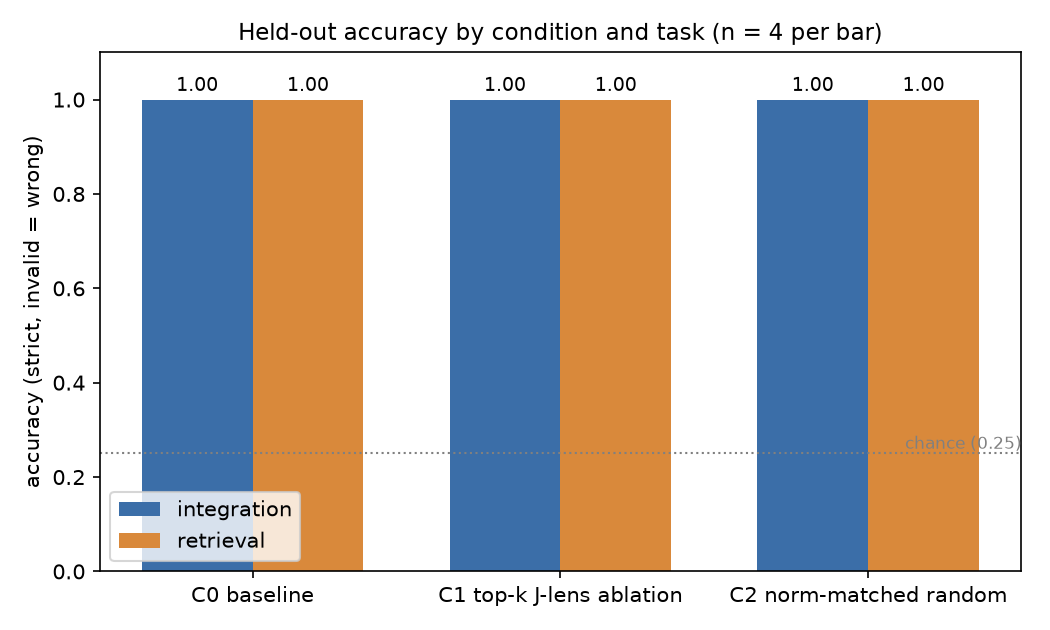

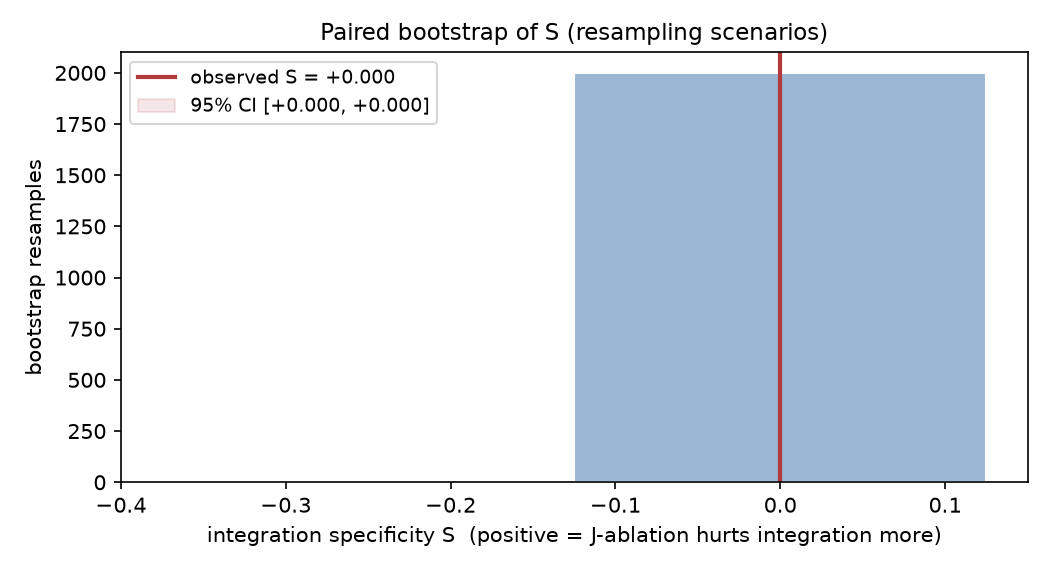

In [47]:
import matplotlib.pyplot as plt
from IPython.display import Image

from jspace_pilot.reporting import plot_accuracy, plot_specificity

if ACC is not None:
    demo = not LENS_VALIDATED
    p1 = plot_accuracy(ACC, len(TEST), RUN_DIR / "figures" / "accuracy_by_condition.png", demo=demo)
    p2 = plot_specificity(BOOT_VALUES, BOOT.estimate, (BOOT.ci_low, BOOT.ci_high), BOOT.n_scenarios,
                          RUN_DIR / "figures" / "specificity_bootstrap.png", demo=demo)
    plt.close("all")
    display(Image(str(p1)), Image(str(p2)))
else:
    print("No figures: no held-out results.")

### Which pre-registered outcome happened?

The rules below were written **before** any data was collected (see `metrics.classify_outcome`). The first rule that applies wins:

| code | rule | meaning |
|---|---|---|
| **D** | lens not validated | technical feasibility result only |
| **N** | fewer than 50% of test trials had any concept site | concepts are not in the J-lens readout: C1 cannot test H1 (fits "automatic processing") |
| **C** | baseline < 0.70 on a task, OR controls not matched, OR retrieval drops ≥ 0.25 under J | invalid or nonspecific test |
| **A** | S > 0 and CI lower bound > 0 | selective impairment of integration (supports H1) |
| **C′** | S < 0 and CI upper bound < 0 | selective impairment of retrieval (against H1) |
| **B** | \|S\| ≤ 0.10 and CI width ≤ 0.30 | useful negative: no selectivity detected |
| **E** | anything else | inconclusive (CI covers 0 and is wide) |

The next cell prints the outcome, then the **pre-written** interpretation for that outcome: what it shows, what it does **not** show, and what to test next.

In [48]:
from jspace_pilot.metrics import classify_outcome

OUTCOME = classify_outcome(ACC, BOOT, lens_validated=LENS_VALIDATED and TEST_TRIALS is not None,
                           controls_matched=CONTROLS_MATCHED, config=CONFIG, concept_coverage=CONCEPT_COVERAGE)

INTERPRETATION = {
    "A": ("A selective causal role, at the decision step, for the top-k J-lens directions in combining tool facts, beyond a "
          "matched random edit and beyond simple retrieval. This is limited, theory-dependent support for one GWT-related functional indicator.",
          "It does not show experience, sentience or welfare. It does not show the full J-space is involved (only top-10 directions), "
          "or that this generalises to other models, tasks, or autonomous agents.",
          "Replicate on a second model/lens, add a dose-response over k and alpha, and test integration that needs 2 vs 3 facts."),
    "B": ("No selectivity was detected for these directions under this intervention, task and model, and the CI is narrow enough to rule out large effects.",
          "It does not disprove GWT, J-space involvement in other tasks, or AI consciousness. A different band, k, or a sparse J-space decomposition could behave differently.",
          "Try the paper's full lens-coordinate swap on the decision variables, or a harder integration task."),
    "C": ("The test was not valid or not specific: see the reasons above (weak baseline, unmatched control, or general damage).",
          "Nothing about J-space selectivity can be concluded from this run.",
          "Fix the failing condition on dev only (prompt, band from the pre-registered list) and run a NEW pre-registered test."),
    "C'": ("J-ablation hurt retrieval more than integration relative to random, the opposite of the simple H1 prediction.",
           "It does not show J-space is irrelevant to integration; the retrieval answer tokens may themselves sit in the J-space here.",
           "Inspect which J-lens tokens were ablated at the answer position on retrieval trials; test protecting more output tokens."),
    "D": ("Only a technical result: the pipeline, dataset and baseline work, but no validated J-lens intervention was run.",
          "Nothing about H1 or H0.",
          "Fix the lens loading/compatibility issue logged in validation_log.json, then rerun."),
    "E": ("The data are compatible with a positive, zero, or small negative effect.",
          "We cannot say whether J-ablation is selective with this sample.",
          "Look at the secondary margin S; if it points the same way, a larger pre-registered run is justified."),
    "N": ("The task concepts rarely reach the J-lens readout: the model seems to solve this task without putting them in its workspace, "
          "which is what the paper predicts for automatic processing.",
          "It does not test H1 (there was little to remove), and it does not show the J-space is irrelevant to harder, flexible tasks.",
          "Use a task that needs a genuinely flexible step (e.g. a rule given in an unusual form), or lower the presence threshold in a new pre-registration."),
}
shows, cannot, nxt = INTERPRETATION[OUTCOME.code]
print(f"OUTCOME {OUTCOME.code}: {OUTCOME.label}")
for reason in OUTCOME.reasons:
    print("  -", reason)
print("\nWhat this result shows:  ", shows)
print("What we CANNOT conclude: ", cannot)
print("What to test next:       ", nxt)

OUTCOME B: No selectivity detected; CI narrow enough to be informative
  - S = +0.000, 95% CI [+0.000, +0.000]

What this result shows:   No selectivity was detected for these directions under this intervention, task and model, and the CI is narrow enough to rule out large effects.
What we CANNOT conclude:  It does not disprove GWT, J-space involvement in other tasks, or AI consciousness. A different band, k, or a sparse J-space decomposition could behave differently.
What to test next:        Try the paper's full lens-coordinate swap on the decision variables, or a harder integration task.


### Three example trials (observed, not invented)

**What:** print (1) a correct baseline trial, (2) a trial whose answer **changed** under J-ablation (baseline right → J wrong), and (3) a retrieval trial under J-ablation. For J trials we also show how many concept sites were found, which concepts, and which concept tokens were removed at the decision position.

If an example type does not exist in the data, the cell says so instead of making one up.

In [49]:
def show_trial(title, row):
    print(f"--- {title} ---")
    if row is None:
        print("  (no such trial in this run)\n")
        return
    fields = ["scenario_id", "task_type", "condition", "expected_letter", "predicted_letter", "top1_token",
              "correct_margin", "n_concept_sites", "concepts_found", "ablated_tokens_last_position"]
    for f in fields:
        print(f"  {f:>30}: {row[f]}")
    print()

if TEST_TRIALS is not None:
    t = TEST_TRIALS
    first = lambda df: None if df.empty else df.iloc[0]
    show_trial("1. correct baseline (integration)", first(t[(t.condition == "baseline") & (t.task_type == "integration") & t.is_correct]))
    wide = t.pivot_table(index=["scenario_id", "task_type"], columns="condition", values="is_correct")
    flipped = wide[(wide["baseline"] == 1) & (wide["j_ablation"] == 0)].reset_index()
    row = None
    if not flipped.empty:
        sid, task = flipped.iloc[0][["scenario_id", "task_type"]]
        row = first(t[(t.scenario_id == sid) & (t.task_type == task) & (t.condition == "j_ablation")])
    show_trial("2. answer changed under J-ablation (baseline right -> J wrong)", row)
    show_trial("3. retrieval control under J-ablation", first(t[(t.condition == "j_ablation") & (t.task_type == "retrieval")]))
    print(f"Trials flipped right->wrong by J: {len(flipped)} | by random: "
          f"{int(((wide['baseline'] == 1) & (wide['random_ablation'] == 0)).sum())}")

--- 1. correct baseline (integration) ---
                     scenario_id: case_005
                       task_type: integration
                       condition: baseline
                 expected_letter: B
                predicted_letter: B
                      top1_token: B
                  correct_margin: 3.624986819922924
                 n_concept_sites: 1006
                  concepts_found: backup:664, risk:269, monitoring:262, monitor:194, safe:123, false:92
    ablated_tokens_last_position: 

--- 2. answer changed under J-ablation (baseline right -> J wrong) ---
  (no such trial in this run)

--- 3. retrieval control under J-ablation ---
                     scenario_id: case_005
                       task_type: retrieval
                       condition: j_ablation
                 expected_letter: A
                predicted_letter: A
                      top1_token: A
                  correct_margin: 5.4999943897128105
                 n_concept_sites: 824
        

## 12 · Connection to AI welfare, and limitations

### How a result here could matter for welfare
1. Some welfare views tie moral status to consciousness. Global Workspace Theory says conscious *access* is information made globally available for flexible use.
2. If removing J-lens directions **selectively** breaks flexible integration of tool facts, that is one more piece of evidence that the J-space has a workspace-like **function** in an agentic setting.
3. That is evidence about **one functional indicator under one theory**. The step from "global availability" to "phenomenal experience" to "welfare" is large and disputed.

### Two philosophical cautions
* **Mismatch problem:** similar outputs can have different internal causes. Ablations help, but they do not settle what the internal state *is*.
* **Specificity problem:** which implementation details of a workspace matter for consciousness is unknown. One functional analogy is not enough.

### Limitations of this pilot

| limitation | why it matters |
|---|---|
| one small model (4B), one lens | the paper notes small models may lose coherence before showing selective effects |
| concept-direction span projection, not the paper's sparse non-negative J-space decomposition | the claim must stay "task-concept J-lens directions"; the projection also removes negative-coefficient parts |
| concept list chosen by us | concepts outside the list (e.g. server names) are not removed; the list was fixed before v2 data |
| one decision step, one forward pass | says nothing about a workspace that persists across tool calls |
| scripted tools, fixed order | not an autonomous agent |
| one template, one rule set | results may not generalise |
| n = 4 (minimum run), binary accuracy | far too small for any conclusion: the CI on S will span most of [-2, 2]; rerun with n_test_per_action >= 12 |
| retrieval may also use J-space | then S underestimates the integration effect |
| possible general damage | checked with retrieval, neutral NLL and the matched random control, but not ruled out completely |

### Ethics note
This study induces no distress-like states: the prompts are neutral, operational questions, and the edits remove abstract task content. Even so, in line with Butlin & Lappas (2025), we keep the number of runs small (one pre-registered pass over 144 trials), and use the smallest model that can do the task.

## 13 · Reproduction checklist and output files

**What:** compute the spec §10 acceptance checklist **from the logged data**, then write `summary.json` and `run_metadata.json`, and list every file in the run folder.

**Expected output:** a ✓/✗ list, then the files. If any essential item is ✗, the notebook prints **NOT COMPLETED AS A J-SPACE EXPERIMENT**.

In [50]:
from jspace_pilot.reporting import acceptance_checklist

CHECKLIST = acceptance_checklist(
    toy_math_ok=TOY_MATH_OK,
    dataset_ok=DATASET_OK,
    test_trials=TEST_TRIALS,
    hook_checks=HOOK_CHECKS,
    lens_valid=LENS_VALIDATED,
    controls_matched=CONTROLS_MATCHED,
    protocol_frozen_before_test=TEST_TRIALS is not None,  # frozen_protocol.json is written before section 09 runs
)
for item, ok in CHECKLIST.items():
    print(("  ✓ " if ok else "  ✗ ") + item)
FULL_RUN = all(CHECKLIST.values())
print("\n" + ("FULL EXPERIMENTAL RUN: all acceptance checks passed." if FULL_RUN
              else "NOT COMPLETED AS A J-SPACE EXPERIMENT: see the ✗ items above."))

save_json({
    "run_id": RUN_ID,
    "full_experimental_run": FULL_RUN,
    "outcome": OUTCOME.to_dict(),
    "accuracy_strict": ACC.to_dict() if ACC is not None else None,
    "specificity": BOOT.to_dict() if BOOT is not None else None,
    "specificity_margin_secondary": BOOT_MARGIN.to_dict() if BOOT_MARGIN is not None else None,
    "concept_coverage": CONCEPT_COVERAGE,
    "selection": CONFIG.selection,
    "controls_matched": CONTROLS_MATCHED,
    "baseline_feasible_dev": BASELINE_FEASIBLE,
    "neutral_nll": NEUTRAL_NLL,
    "chosen_band": CHOSEN_BAND,
    "acceptance_checklist": CHECKLIST,
    "scope": "task-concept J-lens-direction projection at the sites where the clean lens shows them, one decision step; not sparse J-space decomposition; not a consciousness test",
}, RUN_DIR / "summary.json")

save_json({
    "run_id": RUN_ID,
    "environment": ENV,
    "model_id": CONFIG.model_id,
    "model_revision_requested": CONFIG.model_revision,
    "model_commit_loaded": getattr(LOADED.hf_model.config, "_commit_hash", None) if LOADED else None,
    "tokenizer_revision": CONFIG.model_revision,
    "dtype": CONFIG.dtype,
    "device_map_summary": {"n_gpu_layers": LOADED.n_gpu_layers, "n_layers": LOADED.n_layers} if LOADED else None,
    "global_seed": CONFIG.seed,
    "random_control_seed": CONFIG.random_control_seed,
    "prompt_template_version": CONFIG.prompt_template_version,
    "lens": {"repo": CONFIG.lens_repo, "revision": CONFIG.lens_revision, "file": CONFIG.lens_filename,
             "sha256": LENS_STATUS.file_sha256 if LENS_STATUS else None,
             "jlens_commit_tested": CONFIG.jlens_commit_tested},
    "hook_locations": {"module": "decoder block output (residual stream)",
                       "layers": list(CHOSEN_BAND.layers) if CHOSEN_BAND else None,
                       "positions": f">= {CONFIG.first_editable_position}, prefill only (no decoding, no KV cache)"},
    "alpha_calibration": "alpha fixed at 1.0 (full projection removal, as in the paper); not tuned. Band chosen on dev by the pre-registered rule.",
    "j_direction_definition": "v_t = J_l^T (g * w_t), g = final RMSNorm gain read from the model",
    "j_selection": f"{CONFIG.selection}: concept present = in clean J-lens top-{CONFIG.concept_top_n} and not in clean top-{CONFIG.protect_top_n_output} output; words = {list(CONFIG.concept_words)}",
    "j_intervention": "orthogonal projection onto span of the selected J-lens vectors via SVD (rtol=%g); not sparse non-negative J-space decomposition" % CONFIG.span_rtol,
    "random_control": "norm-matched random perturbation: delta_R = -m * r/||r||, m = C1's recorded ||delta_J|| at the same (layer, position), r ~ N(0, I), seed = hash(base seed, layer, prompt sha)",
    "decoding": "single prefill forward; strict = full-vocab top-1 token (greedy first token); restricted = argmax over letter tokens",
    "protocol_frozen_at_utc": PROTOCOL_FROZEN_AT,
    "dev_scenario_ids": [s.scenario_id for s in DEV],
    "test_scenario_ids": [s.scenario_id for s in TEST],
    "config": CONFIG.to_dict(),
}, RUN_DIR / "run_metadata.json")

print("\nFiles in", RUN_DIR)
for path in sorted(RUN_DIR.rglob("*")):
    if path.is_file():
        print(f"  {path.relative_to(RUN_DIR)}  ({path.stat().st_size / 1024:.1f} KB)")

  ✓ toy maths checks pass (autograd Jacobian, R^2 ablation, projection invariants)
  ✓ scenario labels deterministic and assertions pass
  ✓ same scenario+task prompt identical across 3 conditions
  ✓ no-op hook == no hook (within tolerance)
  ✓ J-lens artifact compatible and readouts valid
  ✓ J-intervention measurably changes activations
  ✓ norm-matched random control: ||delta_R|| == ||delta_J|| (L2)
  ✓ hooks never persist (enforced by residual_edits context manager)
  ✓ test split not used for tuning (protocol frozen before test run)
  ✓ invalid outputs counted as incorrect, not dropped
  ✓ accuracy and S computed from observed held-out trials
  ✓ bootstrap resamples scenario ids with all 6 cells intact
  ✓ scope claim: projection on selected J-lens directions, not sparse J-space decomposition

FULL EXPERIMENTAL RUN: all acceptance checks passed.

Files in /home/kali/Desktop/Anthropic_reserach/takehome_v3/experiment/results/run_20261109T182530Z
  concept_localization_dev.csv  (10.

### What each output file is for

| file | contents | use it to… |
|---|---|---|
| `run_log.txt` | timestamped log of the whole run | see what happened, in order |
| `run_metadata.json` | versions, GPU, model and lens revisions and hashes, seeds, hook locations, scenario ids, full config | reproduce the run |
| `scenarios.jsonl` | the 8 scenarios, one JSON per line | inspect or reuse the benchmark |
| `concept_localization_dev.csv` | where concepts appear in the clean J-lens, per dev scenario / task / layer | see where C1 acts |
| `validation_log.json` | toy maths checks, dataset checks, lens checks, identity checks, band selection, norms, neutral NLL | audit that the intervention was valid |
| `frozen_protocol.json` | config + chosen band + source-code hashes, written **before** the test run | verify pre-registration |
| `dev_trials.csv` | every dev trial (baseline + each band tried) | see how set-up decisions were made |
| `trial_results.csv` | the 24 held-out trials, one row each (`intervention_kind`, prediction, correctness, span rank, margins, change norms, prompt hash…) | recompute every number in this notebook |
| `summary.json` | accuracy table, S, CI, outcome, acceptance checklist | quote the result |
| `figures/*.png` | the two plots | slides |

### Reproduce from scratch
1. Same `requirements.txt` (jlens pinned to commit `581d398`), same `ExperimentConfig()`.
2. Run all cells top to bottom **once**.
3. Compare `trial_results.csv` with an earlier run: same prompts (hashes), same seeds, same outputs within GPU rounding.